In [1]:
import os
import sys
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import Normalize
from matplotlib.gridspec import GridSpec
from matplotlib.path import Path as MplPath
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from ladcp_tools import *

In [28]:
# =============================================================================
# Eddy
# =============================================================================
# EVENTS: merging / splitting events as (date, "merging" | "splitting"). They are drawn on
# the maps at the tracked center of that day (with that day's max-speed contour dashed)
# and as dashed vertical lines on the time series.
# TRACK_BACK_TO: also track backwards from START_DATE down to this date (None = forward only).

# AE #11   START_LON, START_LAT = 16.812, -38.562
# NAME = "AE11_20260514"              # used in titles and file names
# EDDY_TYPE = 1              # 1 = anticyclone, -1 = cyclone
# START_LON, START_LAT = 16.8, -38.562
# START_DATE = "2026-05-14"
# TRACK_BACK_TO = None
# EVENTS = [("2026-06-09", "splitting"),
#           ("2026-07-14", "merging")]

# CE #18   START_LON, START_LAT = 17.312, -36.562
# NAME = "eddy_C"              # used in titles and file names
# EDDY_TYPE = -1              # 1 = anticyclone, -1 = cyclone
# START_LON, START_LAT = 17.312, -36.562
# START_DATE = "2026-05-23"
# TRACK_BACK_TO = None
# EVENTS = []
NAME = "CE17_20260512" 
EDDY_TYPE = -1              # 1 = anticyclone, -1 = cyclone
START_DATE = "2026-05-23"
START_LON, START_LAT = 17.312, -36.562   # CE #18: tracked forwards from START_DATE
TRACK_BACK_TO = "2026-05-11"             # also track backwards from START_DATE to this date
BACK_LON, BACK_LAT = 18.938, -37.938     # CE #16: the eddy followed backwards (None = START_LON/LAT)
EVENTS = [("2026-05-16", "merging"),
          ("2026-05-23", "splitting"),
          ("2026-06-01", "merging")]

END_DATE = "2026-07-27"    

PICK_MODE = False            # True: only draw the numbered eddies of START_DATE to choose one

MAX_JUMP_KM = 60.0           # max distance between consecutive daily centers
MAX_MISSED_DAYS = 3          # stop after this many consecutive days without a match
CONTOUR_EVERY = 1          # draw the max-speed contour every N tracked days (0 = never)

# Map extent: None -> automatic around the track
EXTENT = None                # e.g. [8, 25, -41, -34]
PAD_DEG = 1.5

G = 9.81
OMEGA = 7.2921e-5

crs = ccrs.PlateCarree()
ft = 10
R_EARTH_KM = 6371.0
KIND = "anticyclones" if EDDY_TYPE == 1 else "cyclones"


In [29]:
BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives
DIR_EDDIES_BETTER = DIR_EDDIES["TOEDDIES_better_ADT"]
DIR_EDDIES_STD = DIR_EDDIES["TOEDDIES"]
OUT_DIR = BASE / "figures/"
SADCP_TRACK_CSV = BASE / "figures/sadcp_vs_geostrophy/sadcp_vs_geostrophy_track.csv"

In [30]:
def eddy_file(date, kind, part):
    """Path of the <kind>_<part> GeoJSON for this date: better-ADT folder first, then the
    standard one. kind = 'anticyclones'|'cyclones', part = 'centers'|'maxspeed'|'outcontour'."""
    d = pd.Timestamp(date)
    for folder, tag in ((DIR_EDDIES_BETTER, d.strftime("%Y%m%d")),
                        (DIR_EDDIES_STD, d.strftime("%Y-%m-%d")),
                        (DIR_EDDIES_STD, d.strftime("%Y%m%d"))):
        for f in sorted(glob.glob(str(folder / f"*{tag}*"))):
            name = Path(f).name.lower()
            is_anti = "anticyclon" in name
            # careful: "cyclones" is also inside "anticyclones"
            if (kind == "anticyclones") != is_anti:
                continue
            if part in name and name.endswith((".geojson", ".json", ".shp")):
                return f, folder.name
    return None, None

def load_day(date, kind):
    """Centers and contours for one day and one eddy type."""
    fc, src = eddy_file(date, kind, "centers")
    if fc is None:
        return None
    cen = gpd.read_file(fc)
    out = {"centers": cen, "source": src}
    for part in ("maxspeed", "outcontour"):
        fp, _ = eddy_file(date, kind, part)
        out[part] = gpd.read_file(fp) if fp else None
    ok = (cen.geometry.notna() & ~cen.geometry.is_empty).values
    lon = np.full(len(cen), np.nan)
    lat = np.full(len(cen), np.nan)
    lon[ok] = cen.geometry[ok].x.values
    lat[ok] = cen.geometry[ok].y.values
    out["lon"] = np.where(lon > 180, lon - 360, lon)
    out["lat"] = lat
    return out

def haversine_km(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.deg2rad, (lon1, lat1, lon2, lat2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R_EARTH_KM * np.arcsin(np.sqrt(a))

def contour_xy(geom):
    """Outline vertices of a (Multi)Polygon / LineString, NaN vertices removed."""
    if geom is None or geom.is_empty:
        return None
    if geom.geom_type == "Polygon":
        xy = np.asarray(geom.exterior.coords)
    elif geom.geom_type == "MultiPolygon":
        xy = np.asarray(max(geom.geoms, key=lambda g: g.area).exterior.coords)
    elif geom.geom_type in ("LineString", "LinearRing"):
        xy = np.asarray(geom.coords)
    elif geom.geom_type == "MultiLineString":
        xy = np.asarray(max(geom.geoms, key=lambda g: g.length).coords)
    else:
        return None
    xy = xy[:, :2][np.isfinite(xy[:, :2]).all(axis=1)]
    xy[:, 0] = np.where(xy[:, 0] > 180, xy[:, 0] - 360, xy[:, 0])
    return xy if len(xy) > 2 else None


def maxspeed_contour(day, i):
    """Max-speed contour of eddy i. The TOEddies files list eddies in the same order in the
    centers and maxspeed files; if not, use the contour that contains the center."""
    ms = day["maxspeed"]
    if ms is None or len(ms) == 0:
        return None
    if len(ms) == len(day["centers"]):
        xy = contour_xy(ms.geometry.iloc[i])
        if xy is not None:
            return xy
    p = day["centers"].geometry.iloc[i]
    for g in ms.geometry:
        if g is not None and not g.is_empty and g.geom_type.endswith("Polygon") and g.contains(p):
            return contour_xy(g)
    return None

def equivalent_radius_km(xy):
    """Radius of the circle with the same area as the contour (local flat projection)."""
    if xy is None:
        return np.nan
    lat0 = np.deg2rad(np.mean(xy[:, 1]))
    x = np.deg2rad(xy[:, 0]) * R_EARTH_KM * np.cos(lat0)
    y = np.deg2rad(xy[:, 1]) * R_EARTH_KM
    area = 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))
    return np.sqrt(area / np.pi)

def eddy_contour(day, i, part="maxspeed"):
    """Contour of eddy i"""
    gdf = day.get(part)
    if gdf is None or len(gdf) == 0:
        return None
    if len(gdf) == len(day["centers"]):
        xy = contour_xy(gdf.geometry.iloc[i])
        if xy is not None:
            return xy
    p = day["centers"].geometry.iloc[i]
    for g in gdf.geometry:
        if g is not None and not g.is_empty and g.geom_type.endswith("Polygon") and g.contains(p):
            return contour_xy(g)
    return None

def _track_leg(t0, t1, lon0, lat0, first_step_nan=True):
    """Follow the nearest eddy day by day from t0 to t1 (t1 < t0 tracks backwards)."""
    t0, t1 = pd.Timestamp(t0), pd.Timestamp(t1)
    step = pd.Timedelta(days=1) if t1 >= t0 else pd.Timedelta(days=-1)
    cur_x, cur_y = lon0, lat0
    rows, missed = [], 0
    for date in pd.date_range(t0, t1, freq=step):
        day = load_day(date, KIND)
        d = None if day is None else haversine_km(cur_x, cur_y, day["lon"], day["lat"])
        if d is None or np.all(np.isnan(d)):
            print(f"{date:%Y-%m-%d}  no {KIND} file, skipped")
            missed += 1
        else:
            i = int(np.nanargmin(d))
            limit = MAX_JUMP_KM * (missed + 1)          # allow a longer jump after gaps
            if d[i] > limit:
                print(f"{date:%Y-%m-%d}  nearest is {d[i]:.0f} km away (> {limit:.0f} km), skipped")
                missed += 1
            else:
                xc, yc = day["lon"][i], day["lat"][i]
                ms, oc = eddy_contour(day, i, "maxspeed"), eddy_contour(day, i, "outcontour")
                props = eddy_properties(load_adt_day(date), xc, yc, ms, oc)
                rows.append(dict(date=date, lon=xc, lat=yc, index_in_file=i,
                                 source=day["source"], contour=ms, outcontour=oc, **props))
                p = rows[-1]
                print(f"{date:%Y-%m-%d} {i:>4} {xc:8.3f} {yc:8.3f} {d[i]:6.1f}k "
                      f"{p['r_maxspeed_km']:5.0f}k {p['vmax']:6.2f} {p['amplitude_cm']:5.1f}c "
                      f"{p['rossby']:6.3f}")
                cur_x, cur_y, missed = xc, yc, 0
        if missed > MAX_MISSED_DAYS:
            print(f"Lost the eddy after {MAX_MISSED_DAYS} days without a match: stop.")
            break
    return rows


def track():
    print(f"{'date':10} {'#':>4} {'lon':>8} {'lat':>8} {'moved':>7} {'Rmax':>6} "
          f"{'Vmax':>6} {'Amp':>6} {'Ro':>6}")
    rows = _track_leg(START_DATE, END_DATE, START_LON, START_LAT)
    if TRACK_BACK_TO is not None and pd.Timestamp(TRACK_BACK_TO) < pd.Timestamp(START_DATE):
        print(f"--- backwards from {START_DATE} to {TRACK_BACK_TO} ---")
        t_start = pd.Timestamp(START_DATE)
        first = rows[0] if rows and rows[0]["date"] == t_start else None
        x0, y0 = (first["lon"], first["lat"]) if first else (START_LON, START_LAT)
        rows = _track_leg(t_start - pd.Timedelta(days=1), TRACK_BACK_TO, x0, y0) + rows

    tr = pd.DataFrame(rows)
    if tr.empty:
        raise RuntimeError("No eddy found: check START_LON/LAT, START_DATE and EDDY_TYPE "
                           "(run with PICK_MODE = True).")
    tr = tr.sort_values("date").reset_index(drop=True)
    # step between consecutive tracked centers and translation speed (km/day),
    # robust to skipped days
    ddays = tr.date.diff().dt.total_seconds() / 86400
    tr["step_km"] = haversine_km(tr.lon.shift(), tr.lat.shift(), tr.lon, tr.lat)
    tr["speed_km_day"] = tr.step_km / ddays
    tr.drop(columns=["contour", "outcontour"]).to_csv(OUT_DIR / f"tracked_eddy_{NAME}.csv",
                                                       index=False)
    return tr


# ---------------- merging / splitting events ----------------
EVENT_STYLE = {"merging": dict(marker="P", color="magenta"),
               "splitting": dict(marker="X", color="cyan")}


def event_rows(tr, verbose=False):
    """(date, kind, tracked row) for each entry of EVENTS. If the event day was not
    tracked (skipped), the nearest tracked day is used; events more than
    MAX_MISSED_DAYS from the track are left out."""
    out = []
    for d, kind in (EVENTS if "EVENTS" in globals() else []):
        kind = kind.lower().strip()
        if kind not in EVENT_STYLE:
            raise ValueError(f"event kind must be 'merging' or 'splitting', not {kind!r}")
        d = pd.Timestamp(d).normalize()
        k = (tr.date.dt.normalize() - d).abs().idxmin()
        gap = abs((tr.date[k].normalize() - d).days)
        if gap > MAX_MISSED_DAYS:
            if verbose:
                print(f"  ! {kind} on {d:%Y-%m-%d}: eddy not tracked within "
                      f"{MAX_MISSED_DAYS} days, not drawn")
            continue
        if gap and verbose:
            print(f"  {kind} on {d:%Y-%m-%d}: not tracked that day, drawn at "
                  f"{tr.date[k]:%Y-%m-%d}")
        out.append((d, kind, tr.loc[k]))
    return out


def draw_events(ax, tr):
    """Event markers + dated labels on a map, event-day max-speed contour dashed.
    Returns the legend handles."""
    handles, seen = [], set()
    for d, kind, row in event_rows(tr, verbose=True):
        st = EVENT_STYLE[kind]
        # xy = row["contour"]
        # if xy is not None:
        #     ax.plot(xy[:, 0], xy[:, 1], color=st["color"], lw=1.8, ls="--",
        #             transform=crs, zorder=11)
        ax.scatter(row["lon"], row["lat"], marker=st["marker"], s=130, c=st["color"],
                   edgecolors="k", linewidths=0.8, transform=crs, zorder=15)
        ax.annotate(f"{d:%d %b}", xy=(row["lon"], row["lat"]),
                    xycoords=crs._as_mpl_transform(ax), xytext=(7, 7),
                    textcoords="offset points", fontsize=7, fontweight="bold", zorder=16,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=st["color"], alpha=0.9))
        if kind not in seen:
            seen.add(kind)
            handles.append(mlines.Line2D([], [], marker=st["marker"], ls="--",
                                         color=st["color"], mec="k", ms=9,
                                         label=f"{kind.capitalize()} event"))
    return handles

def setup_map(fig, extent, sub=111):
    proj = ccrs.Mercator(central_longitude=(extent[0] + extent[1]) / 2)
    ax = fig.add_subplot(sub, projection=proj)
    ax.set_extent(extent, crs=crs)
    ax.add_feature(cfeature.LAND, edgecolor="black", facecolor="gray", zorder=3)
    ax.coastlines(resolution="10m", color="k", linewidth=0.6, zorder=4)
    gl = ax.gridlines(linewidth=1, color="black", alpha=0.2, linestyle="--",
                      draw_labels=True, zorder=6)
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {"size": ft}
    b = xr.open_dataset(FNAME_BATHY)
    x0, x1, y0, y1 = extent
    topo = b["topo"].sel(lon=slice(x0 - 1, x1 + 1), lat=slice(y0 - 1, y1 + 1))
    c = ax.contourf(topo.lon, topo.lat, topo, np.arange(-5500, 1, 500),
                    transform=crs, cmap="Blues_r", zorder=0, alpha=0.85, extend="min")
    return ax, c

def plot_track_eddy(tr):
    if EXTENT is not None:
        extent = EXTENT
    else:
        xs = np.concatenate([tr.lon.values] + [c[:, 0] for c in tr.contour if c is not None])
        ys = np.concatenate([tr.lat.values] + [c[:, 1] for c in tr.contour if c is not None])
        extent = [xs.min() - PAD_DEG, xs.max() + PAD_DEG, ys.min() - PAD_DEG, ys.max() + PAD_DEG]

    fig = plt.figure(figsize=(8, 8), dpi=300)
    ax, c = setup_map(fig, extent)

    tnum = mdates.date2num(tr.date)
    norm = Normalize(vmin=tnum.min(), vmax=tnum.max() if tnum.max() > tnum.min() else tnum.min() + 1)
    cmap = plt.get_cmap("autumn")

    ax.plot(tr.lon, tr.lat, "-", color="k", lw=0.8, transform=crs, zorder=9)
    if CONTOUR_EVERY:
        idx = list(range(0, len(tr), CONTOUR_EVERY))
        if idx[-1] != len(tr) - 1:
            idx.append(len(tr) - 1)
        for k in idx:
            xy = tr.contour[k]
            if xy is not None:
                ax.plot(xy[:, 0], xy[:, 1], color=cmap(norm(tnum[k])), lw=1.2,
                        transform=crs, zorder=8)
    ax.scatter(tr.lon, tr.lat, c=tnum, cmap=cmap, norm=norm, s=14, edgecolors="k",
               linewidths=0.3, transform=crs, zorder=10)
    ax.scatter(START_LON, START_LAT, marker="*", s=120, c="yellow", edgecolors="k",
               transform=crs, zorder=11)

    typ = "Anticyclone" if EDDY_TYPE == 1 else "Cyclone"
    ax.set_title(f"{typ} {NAME}: tracked centers "
                 f"({tr.date.min():%b %d} – {tr.date.max():%b %d, %Y})", fontsize=12)
    ax.legend(handles=[
        mlines.Line2D([], [], marker="o", ls="-", color="k", mfc="orange", ms=5,
                      label="Daily center"),
        mlines.Line2D([], [], color="orange", lw=1.2,
                      label=f"Max-speed contour (every {CONTOUR_EVERY} d)"),
        mlines.Line2D([], [], marker="*", ls="", mfc="yellow", mec="k", ms=10,
                      label="Starting point"),
    ] + draw_events(ax, tr), loc="upper right", fontsize=7, framealpha=0.9).set_zorder(20)

    # depth colorbar under the map, date colorbar on the side (as in the MSM40 figure)
    cax = inset_axes(ax, width="80%", height="3%", loc="lower center",
                     bbox_to_anchor=(0, -0.12, 1, 1), bbox_transform=ax.transAxes, borderpad=0)
    cb = fig.colorbar(c, cax=cax, orientation="horizontal")
    cb.set_label("Depth [m]", fontsize=10)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb2 = fig.colorbar(sm, ax=ax, orientation="vertical", shrink=0.6, pad=0.03)
    cb2.ax.yaxis.set_major_locator(mdates.AutoDateLocator(maxticks=6))
    cb2.ax.yaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    cb2.set_label("Date", fontsize=9)

    out = OUT_DIR / f"tracked_eddy_{NAME}.png"
    fig.savefig(out, bbox_inches="tight")
    print(f"saved {out}")
    plt.show()

def contour_of_day(tr, t, part="outcontour"):
    """Contour of the tracked eddy on the day of time t (falls back to max-speed)."""
    row = tr[tr.date == pd.Timestamp(t).normalize()]
    if row.empty:
        return None
    xy = row.iloc[0][part]
    return xy if xy is not None else row.iloc[0]["outcontour"]

def inside(xy, lon, lat):
    """Boolean mask of points (lon, lat) inside contour xy."""
    if xy is None:
        return np.zeros(np.shape(lon), bool)
    pts = np.c_[np.ravel(lon), np.ravel(lat)]
    return MplPath(xy).contains_points(pts).reshape(np.shape(lon))


def ladcp_in_eddy(tr):
    """LADCP stations inside the eddy's outermost contour on the day of the cast."""
    empty = pd.DataFrame(columns=["station", "datetime", "lon", "lat", "in_rmax"])
    try:
        sys.path.insert(0, str(DIR_CODE))
        st = load_all_stations(str(DIR_LADCP) + "/")
    except Exception as e:
        print(f"  LADCP stations not loaded ({e})")
        return empty
    tcol = "datetime" if "datetime" in st.columns else st.select_dtypes("datetime").columns[0]
    rows = []
    for _, s in st.iterrows():
        oc = contour_of_day(tr, s[tcol])
        if oc is not None and inside(oc, [s.lon], [s.lat])[0]:
            ms = contour_of_day(tr, s[tcol], "outcontour")
            rows.append(dict(station=s.get("station", ""), datetime=pd.Timestamp(s[tcol]),
                             lon=s.lon, lat=s.lat,
                             in_rmax=bool(ms is not None and inside(ms, [s.lon], [s.lat])[0])))
    return pd.DataFrame(rows) if rows else empty

def ship_in_eddy(tr):
    """Hourly SADCP positions that fall inside the eddy's outermost contour."""
    df = pd.read_csv(SADCP_TRACK_CSV, parse_dates=[0]).rename(columns=lambda c: c.strip())
    df = df.rename(columns={df.columns[0]: "time"}).dropna(subset=["lon", "lat"])
    keep = []
    for day, g in df.groupby(df.time.dt.normalize()):
        xy = contour_of_day(tr, day)
        if xy is not None:
            keep.append(g[inside(xy, g.lon.values, g.lat.values)])
    return pd.concat(keep) if keep else pd.DataFrame(columns=["time", "lon", "lat"])

def track_extent(tr):
    if EXTENT is not None:
        return EXTENT
    xs = np.concatenate([tr.lon.values] + [c[:, 0] for c in tr.contour if c is not None])
    ys = np.concatenate([tr.lat.values] + [c[:, 1] for c in tr.contour if c is not None])
    return [xs.min() - PAD_DEG, xs.max() + PAD_DEG, ys.min() - PAD_DEG, ys.max() + PAD_DEG]

def draw_track(ax, tr, ship=None, stations=None, legend_fs=7):
    """Track, dated centers, contours every CONTOUR_EVERY days, start, in-situ sampling."""
    tnum = mdates.date2num(tr.date)
    norm = Normalize(vmin=tnum.min(), vmax=max(tnum.max(), tnum.min() + 1))
    cmap = plt.get_cmap("autumn")
    ax.plot(tr.lon, tr.lat, "-", color="k", lw=0.8, transform=crs, zorder=9)
    if CONTOUR_EVERY:
        idx = list(range(0, len(tr), CONTOUR_EVERY))
        if idx[-1] != len(tr) - 1:
            idx.append(len(tr) - 1)
        for k in idx:
            xy = tr.contour[k]
            if xy is not None:
                ax.plot(xy[:, 0], xy[:, 1], color=cmap(norm(tnum[k])), lw=1.2,
                        transform=crs, zorder=8)
    ax.scatter(tr.lon, tr.lat, c=tnum, cmap=cmap, norm=norm, s=14, edgecolors="k",
               linewidths=0.3, transform=crs, zorder=10)
    ax.scatter(START_LON, START_LAT, marker="*", s=120, c="yellow", edgecolors="k",
               transform=crs, zorder=11)
    handles = [
        mlines.Line2D([], [], marker="o", ls="-", color="k", mfc="orange", ms=5,
                      label="Daily center"),
        mlines.Line2D([], [], color="orange", lw=1.2,
                      label=f"Max-speed contour (every {CONTOUR_EVERY} d)"),
        mlines.Line2D([], [], marker="*", ls="", mfc="yellow", mec="k", ms=10,
                      label="Starting point"),
    ]
    if ship is not None and len(ship):
        ax.scatter(ship.lon, ship.lat, s=2, c="k", transform=crs, zorder=12)
        handles.append(mlines.Line2D([], [], marker=".", ls="", color="k",
                                     label="Ship (SADCP) inside eddy"))
    if stations is not None and len(stations):
        ax.scatter(stations.lon, stations.lat, marker="^", s=40, c="lime", edgecolors="k",
                   transform=crs, zorder=13)
        for _, s in stations.iterrows():
            ax.text(s.lon + 0.05, s.lat + 0.05, str(s.station), fontsize=6, transform=crs,
                    zorder=14)
        handles.append(mlines.Line2D([], [], marker="^", ls="", mfc="lime", mec="k",
                                     label="LADCP station inside eddy"))
    handles += draw_events(ax, tr)
    ax.legend(handles=handles, loc="upper right", fontsize=legend_fs,
              framealpha=0.9).set_zorder(20)
    return cmap, norm


def plot_eddy_stats(tr, ship, stations):
    """Figure like Fig. 2 of Subirade et al. (2023)."""
    extent = track_extent(tr)
    fig = plt.figure(figsize=(16, 10), dpi=200)
    gs = GridSpec(4, 3, figure=fig, width_ratios=[1.5, 1, 1], hspace=0.45, wspace=0.28)
    ax, c = setup_map(fig, extent, gs[:, 0])
    cmap, norm = draw_track(ax, tr, ship, stations, legend_fs=6)
    ax.set_title("(a) Trajectory and in-situ sampling", loc="left", fontsize=10)
    cax = inset_axes(ax, width="80%", height="2.5%", loc="lower center",
                     bbox_to_anchor=(0, -0.10, 1, 1), bbox_transform=ax.transAxes, borderpad=0)
    fig.colorbar(c, cax=cax, orientation="horizontal").set_label("Depth [m]", fontsize=9)

    anom = "ke_from_anomaly" in tr and tr.ke_from_anomaly.fillna(False).astype(bool).all()
    ke_label = "EKE [cm$^2$ s$^{-2}$]" if anom else "KE (total) [cm$^2$ s$^{-2}$]"
    panels = [("r_maxspeed_km", "(b) Radius of max. velocity", "R$_{max}$ [km]"),
              ("vmax", "(c) Max. azimuthal velocity", "V$_{max}$ [m s$^{-1}$]"),
              ("amplitude_cm", "(d) Amplitude", "Amplitude [cm]"),
              ("eke", "(e) Kinetic energy", ke_label),
              ("rossby", "(f) Rossby number", "Ro = V$_{max}$ / (|f| R$_{max}$)"),
              ("speed_km_day", "(g) Translation speed", "Speed [km day$^{-1}$]")]
    slots = [gs[0, 1], gs[0, 2], gs[1, 1], gs[1, 2], gs[2, 1], gs[2, 2]]
    events = event_rows(tr)
    sampled_days = sorted(set(pd.to_datetime(ship.time).dt.normalize()) if len(ship) else set())
    axes = []
    for (col, title, ylab), slot in zip(panels, slots):
        a = fig.add_subplot(slot, sharex=axes[0] if axes else None)
        for d in sampled_days:                  # days the ship was inside the eddy
            a.axvspan(d, d + pd.Timedelta(days=1), color="0.8", lw=0, zorder=0)
        for t in (stations.datetime if len(stations) else []):
            a.axvline(t, color="g", lw=0.8, zorder=1)
        for d, kind, _ in events:
            a.axvline(d, color=EVENT_STYLE[kind]["color"], lw=1.5, ls="--", zorder=1)
        a.plot(tr.date, tr[col], "-", color="k", lw=1, zorder=2)
        a.scatter(tr.date, tr[col], c=mdates.date2num(tr.date), cmap=cmap, norm=norm, s=10,
                  edgecolors="k", linewidths=0.2, zorder=3)
        a.set_title(title, loc="left", fontsize=10)
        a.set_ylabel(ylab, fontsize=8)
        a.grid(alpha=0.3)
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=5))
        a.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
        a.tick_params(labelsize=8)
        axes.append(a)

    # summary box in the free slot
    tb = fig.add_subplot(gs[3, 1:])
    tb.axis("off")
    lines = [f"{'Anticyclone' if EDDY_TYPE == 1 else 'Cyclone'} {NAME}",
             f"Tracked {tr.date.min():%Y-%m-%d} → {tr.date.max():%Y-%m-%d} "
             f"({len(tr)} days detected), distance covered {np.nansum(tr.step_km):.0f} km",
             f"Mean ± std:  R$_{{max}}$ {tr.r_maxspeed_km.mean():.0f} ± {tr.r_maxspeed_km.std():.0f} km"
             f"   V$_{{max}}$ {tr.vmax.mean():.2f} ± {tr.vmax.std():.2f} m/s"
             f"   amplitude {tr.amplitude_cm.mean():.1f} ± {tr.amplitude_cm.std():.1f} cm",
             f"                    Ro {tr.rossby.mean():.3f} ± {tr.rossby.std():.3f}"
             f"   translation {tr.speed_km_day.mean():.1f} ± {tr.speed_km_day.std():.1f} km/day",
             "Grey bands: ship (SADCP) inside the outermost contour.  "
             "Green lines: LADCP stations inside the eddy."]
    if events:
        lines.append("Events: " + ", ".join(f"{k} {d:%d %b}" for d, k, _ in events)
                     + "  (dashed: magenta = merging, cyan = splitting)")
    tb.text(0, 0.95, "\n".join(lines), va="top", fontsize=9, family="monospace")

    fig.suptitle(f"Eddy {NAME}: trajectory and properties from TOEddies / ADT", fontsize=13, y=0.97)
    # out = OUT_DIR / f"fig2_like_{NAME}.png"
    # fig.savefig(out, bbox_inches="tight")
    plt.close(fig)
    # print(f"saved {out}")

def _on_contour(da, xy):
    return da.interp(lon=xr.DataArray(xy[:, 0], dims="p"),
                     lat=xr.DataArray(xy[:, 1], dims="p")).values

def _subgrid(ds, xy, pad=0.3):
    s = ds.sel(lon=slice(xy[:, 0].min() - pad, xy[:, 0].max() + pad),
               lat=slice(xy[:, 1].min() - pad, xy[:, 1].max() + pad))
    LON, LAT = np.meshgrid(s.lon.values, s.lat.values)
    return s, inside(xy, LON, LAT)

def eddy_properties(ds, xc, yc, ms, oc):
    """Rmax, Vmax, amplitude, (E)KE and Ro of one eddy on one day."""
    out = dict(r_maxspeed_km=equivalent_radius_km(ms), vmax=np.nan, amplitude_cm=np.nan,
               eke=np.nan, rossby=np.nan)
    if ds is None:
        return out
    if ms is not None:
        # azimuthal velocity along the max-speed contour (+ = anticlockwise)
        u, v = _on_contour(ds.ugos, ms), _on_contour(ds.vgos, ms)
        dx = np.deg2rad(ms[:, 0] - xc) * R_EARTH_KM * 1e3 * np.cos(np.deg2rad(yc))
        dy = np.deg2rad(ms[:, 1] - yc) * R_EARTH_KM * 1e3
        r = np.hypot(dx, dy)
        vt = (u * (-dy) + v * dx) / np.where(r > 0, r, np.nan)
        out["vmax"] = abs(np.nanmean(vt))
        # (eddy) kinetic energy inside the max-speed contour
        s, m = _subgrid(ds, ms)
        if m.any():
            ua, va = ("ugosa", "vgosa") if "ugosa" in s else ("ugos", "vgos")
            ke = 0.5 * (s[ua].values ** 2 + s[va].values ** 2)
            out["eke"] = np.nanmean(ke[m]) * 1e4          # m2/s2 -> cm2/s2
            out["ke_from_anomaly"] = ua == "ugosa"
        f0 = abs(2 * OMEGA * np.sin(np.deg2rad(yc)))
        out["rossby"] = out["vmax"] / (f0 * out["r_maxspeed_km"] * 1e3)
    edge = oc if oc is not None else ms
    if edge is not None:
        s, m = _subgrid(ds, edge)
        if m.any():
            a = s.adt.values[m]
            ext = np.nanmax(a) if EDDY_TYPE == 1 else np.nanmin(a)
            out["amplitude_cm"] = abs(ext - np.nanmean(_on_contour(ds.adt, edge))) * 100
    return out

def load_adt_day(date):
    """ADT (+ geostrophic velocities) of one day, or None if there is no file."""
    d = pd.Timestamp(date)
    tags = (d.strftime("%Y-%m-%d"), d.strftime("%Y%m%d"))
    files = [f for f in sorted(glob.glob(str(DIR_SSH / "*.nc")))
             if any(t in Path(f).name for t in tags)]
    if not files:
        return None
    ds = xr.open_dataset(files[0])
    ren = {k: v for k, v in {"latitude": "lat", "longitude": "lon"}.items() if k in ds.variables}
    ds = ds.rename(ren)
    if "time" in ds.dims:
        ds = ds.isel(time=0, drop=True)
    keep = [k for k in ("adt", "ugos", "vgos", "ugosa", "vgosa") if k in ds]
    ds = ds[keep].load()
    ds.close()
    ds = ds.assign_coords(lon=xr.where(ds.lon > 180, ds.lon - 360, ds.lon)).sortby(["lat", "lon"])
    if "ugos" not in ds:                         # compute geostrophy from ADT
        latr = np.deg2rad(ds.lat)
        f = 2 * OMEGA * np.sin(latr)
        deg = np.pi / 180
        ds["ugos"] = -(G / f) * ds.adt.differentiate("lat") / (R_EARTH_KM * 1e3 * deg)
        ds["vgos"] = (G / f) * ds.adt.differentiate("lon") / (R_EARTH_KM * 1e3 * np.cos(latr) * deg)
    return ds
def plot_track(tr, ship, stations):
    """The MSM40-style figure."""
    extent = track_extent(tr)
    fig = plt.figure(figsize=(8, 8), dpi=300)
    ax, c = setup_map(fig, extent)
    cmap, norm = draw_track(ax, tr, ship, stations)
    typ = "Anticyclone" if EDDY_TYPE == 1 else "Cyclone"
    ax.set_title(f"{typ} {NAME}: tracked centers "
                 f"({tr.date.min():%b %d} – {tr.date.max():%b %d, %Y})", fontsize=12)
    cax = inset_axes(ax, width="80%", height="3%", loc="lower center",
                     bbox_to_anchor=(0, -0.12, 1, 1), bbox_transform=ax.transAxes, borderpad=0)
    fig.colorbar(c, cax=cax, orientation="horizontal").set_label("Depth [m]", fontsize=10)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cb2 = fig.colorbar(sm, ax=ax, orientation="vertical", shrink=0.6, pad=0.03)
    cb2.ax.yaxis.set_major_locator(mdates.AutoDateLocator(maxticks=6))
    cb2.ax.yaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    cb2.set_label("Date", fontsize=9)
    # out = OUT_DIR / f"tracked_eddy_{NAME}.png"
    # fig.savefig(out, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    # print(f"saved {out}")

In [31]:
tr = track()

date          #      lon      lat   moved   Rmax   Vmax    Amp     Ro
2026-05-23   18   17.312  -36.562    0.1k    51k   0.45  13.5c  0.102
2026-05-24   19   17.312  -36.562    0.0k    52k   0.44  18.1c  0.098
2026-05-25   15   17.187  -36.562   11.2k    61k   0.45  21.7c  0.084
2026-05-26   16   16.812  -36.438   36.3k   nank    nan   9.0c    nan
2026-05-27   16   16.812  -36.438    0.0k   nank    nan  11.2c    nan
2026-05-28   20   16.562  -36.312   26.3k    42k   0.34   9.4c  0.092
2026-05-29   19   16.437  -36.312   11.2k    43k   0.42  12.0c  0.113
2026-05-30   16   16.312  -36.312   11.2k    41k   0.30  10.3c  0.086
2026-05-31   20   16.437  -36.187   17.9k    50k   0.20  12.7c  0.047
2026-06-01  nearest is 112 km away (> 60 km), skipped
2026-06-02  nearest is 124 km away (> 120 km), skipped
2026-06-03   18   15.062  -36.062  124.3k    52k   0.83  46.0c  0.186
2026-06-04   19   14.937  -36.062   11.2k    53k   0.86  50.8c  0.191
2026-06-05   18   14.812  -36.062   11.2k    50k   

  merging on 2026-06-01: not tracked that day, drawn at 2026-05-31
saved /Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/tracked_eddy_CE17_20260512.png


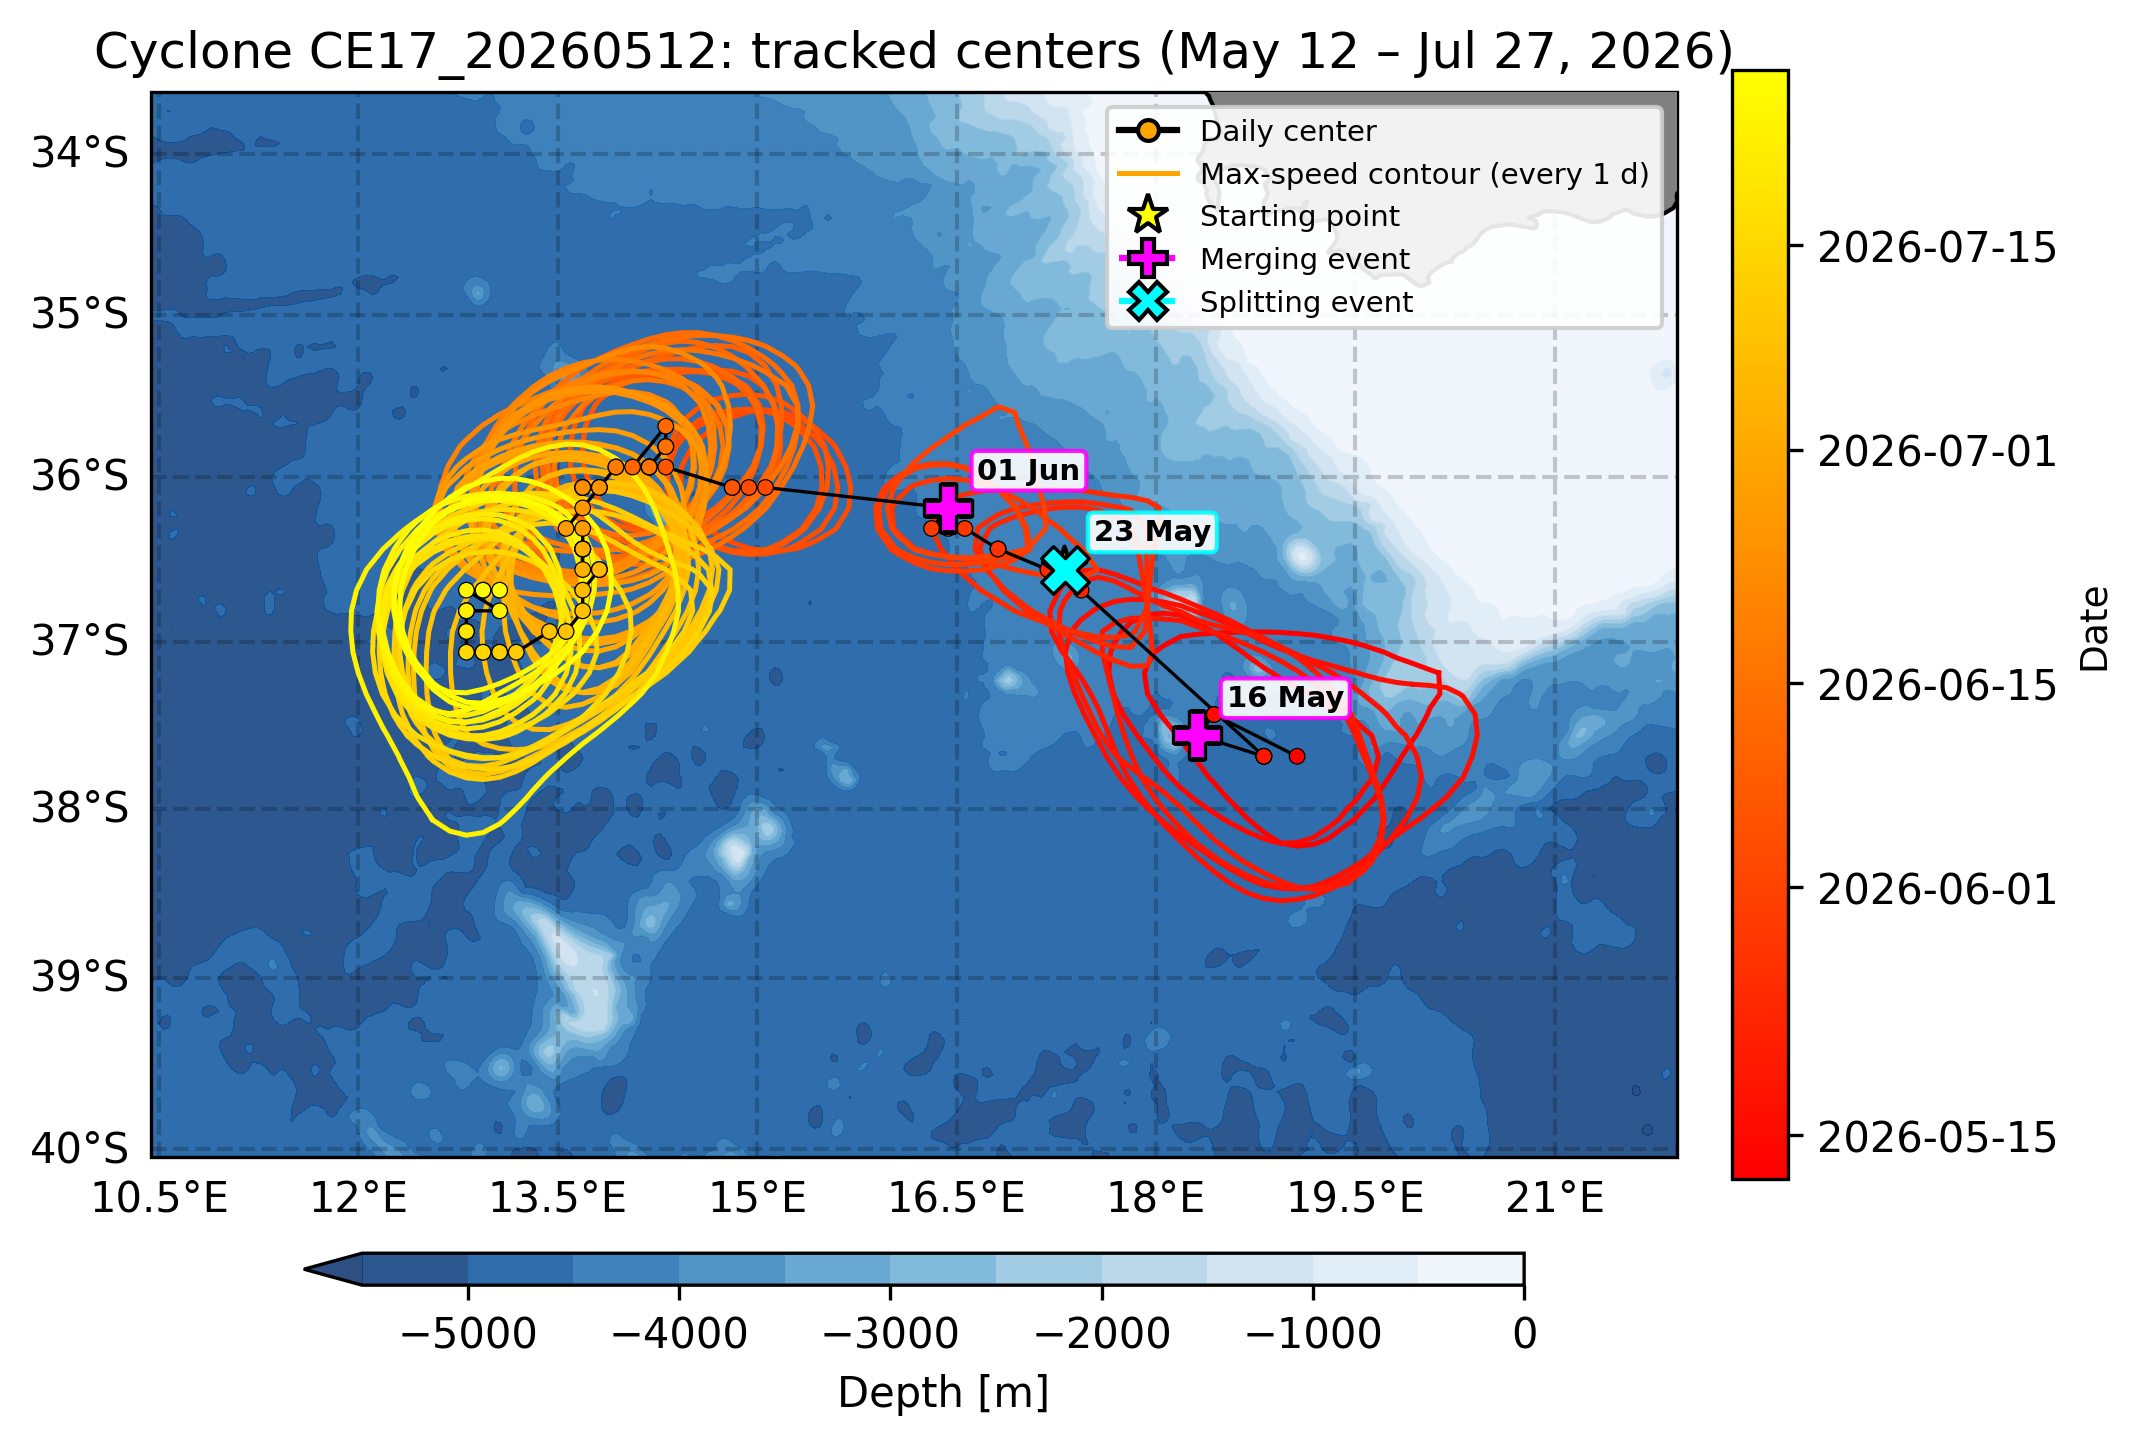

In [32]:
plot_track_eddy(tr)

In [15]:
ship = ship_in_eddy(tr)
stations = ladcp_in_eddy(tr)

Found 58 stations in /Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/LADCP/traitement_avec_SADCP/



64 days tracked, 765 km covered, mean translation 10.8 km/day, mean Rmax 69 km, mean Vmax 0.66 m/s
Ship inside the eddy on 13 day(s); 18 LADCP station(s) inside: 055, 058, 060, 062, 065, 067, 069, 071, 073, 074, 085, 087, 088, 089, 091, 092, 093, 095


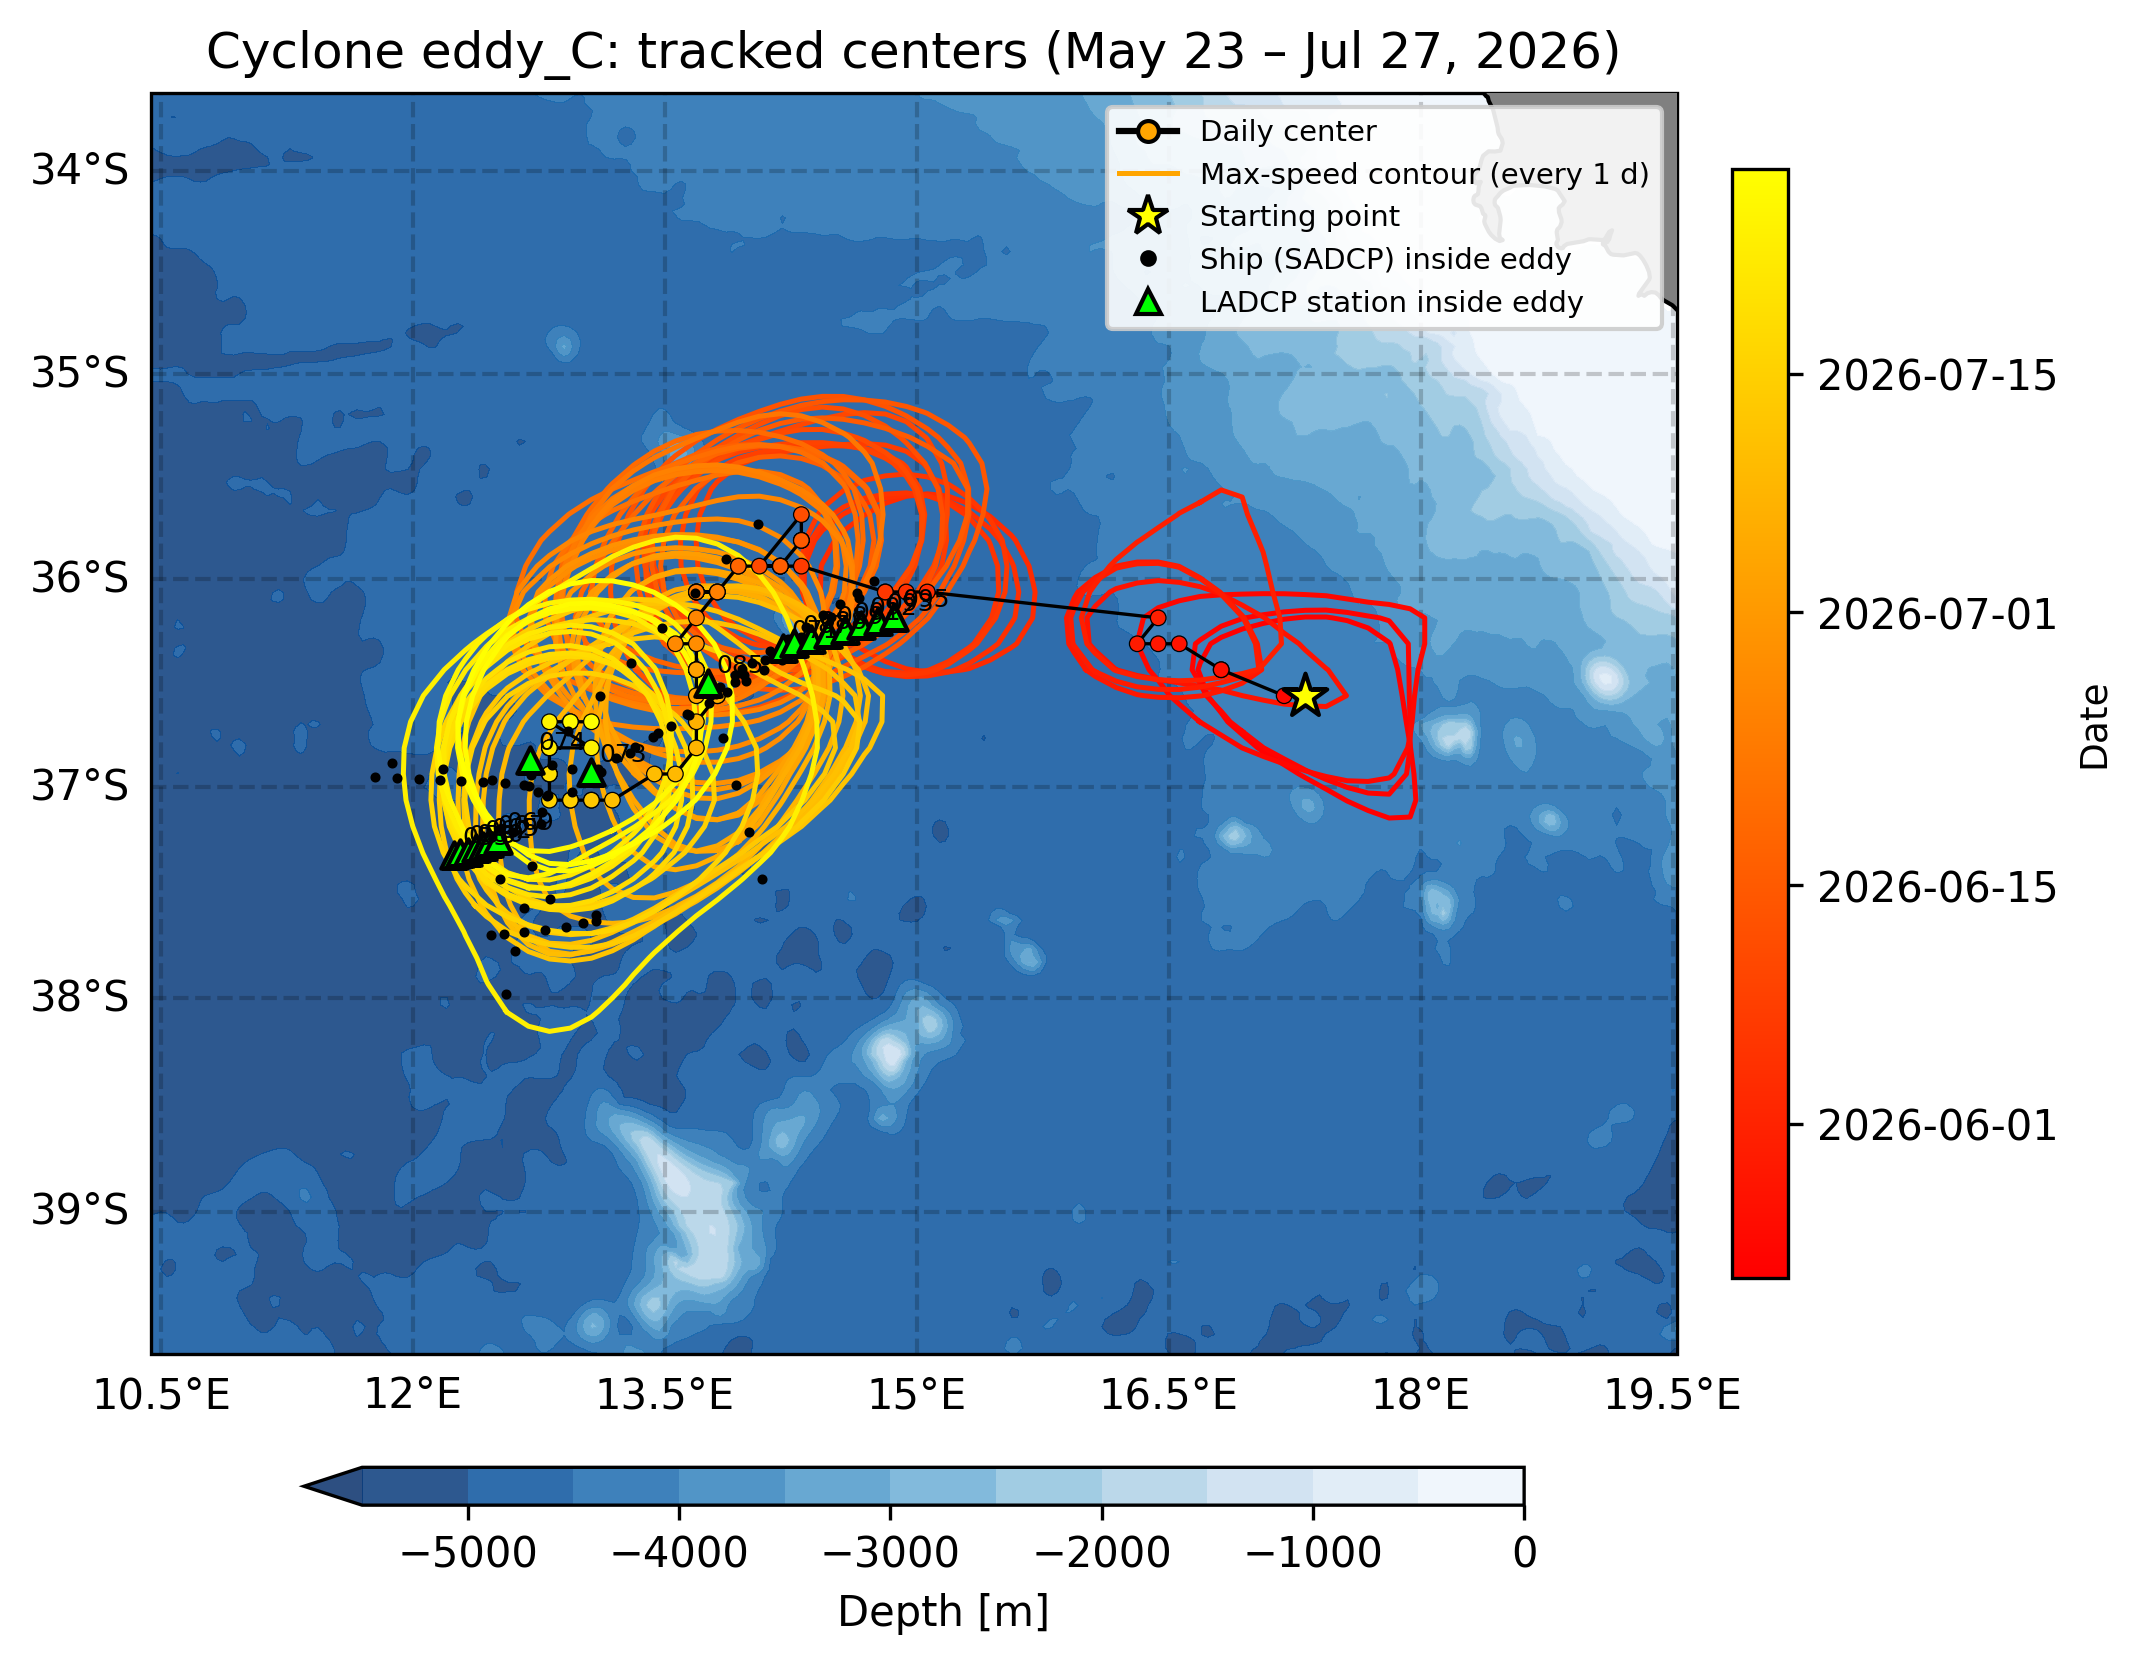

/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_52171/4200095095.py:337: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  anom = "ke_from_anomaly" in tr and tr.ke_from_anomaly.fillna(False).astype(bool).all()


In [16]:
print(f"\n{len(tr)} days tracked, {np.nansum(tr.step_km):.0f} km covered, "
              f"mean translation {tr.speed_km_day.mean():.1f} km/day, "
              f"mean Rmax {tr.r_maxspeed_km.mean():.0f} km, mean Vmax {tr.vmax.mean():.2f} m/s")
print(f"Ship inside the eddy on {ship.time.dt.normalize().nunique() if len(ship) else 0} "
        f"day(s); {len(stations)} LADCP station(s) inside: "
        f"{', '.join(map(str, stations.station)) if len(stations) else '-'}")
if len(stations):
        stations.to_csv(OUT_DIR / f"ladcp_in_{NAME}.csv", index=False)
plot_track(tr, ship, stations)
plot_eddy_stats(tr, ship, stations)